In [1]:
%load_ext autoreload
%autoreload 2
import emcee
from multiprocessing import Pool
from mcmc_script_functions import *

from statistics_functions import log_lik

In [2]:
nfws_subset, L_obs, variances_obs = create_cluster_objects(0.001)

created objects


In [3]:
initial = create_initial_state(8, 2)
initial

array([[-39.2618105 ,  -3.37680454],
       [-26.21848664,  -1.85039227],
       [-32.10462169,  -1.16692538],
       [-35.27984151,  -1.42035509],
       [-32.88320985,  -2.07522918],
       [-24.67916571,  -1.36502265],
       [-25.48346431,  -2.25077453],
       [-36.15172057,  -1.79051195]])

In [16]:
nwalkers=8
ndim=2
#mult_factor=1
agn_model='iqbal'
nclusters = 49
fx = 0.5

In [17]:
with Pool() as pool:
    sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[L_obs[:nclusters], nfws_subset[:nclusters], variances_obs[:nclusters], fx])
    state = sampler.run_mcmc(initial, 1000, progress=True)
    #sampler.reset()

100%|███████████████████████████████████████| 1000/1000 [01:44<00:00,  9.56it/s]


In [ ]:
with Pool() as pool:
    state_f = sampler.run_mcmc(state, 5000, progress=True)

(528, 2)


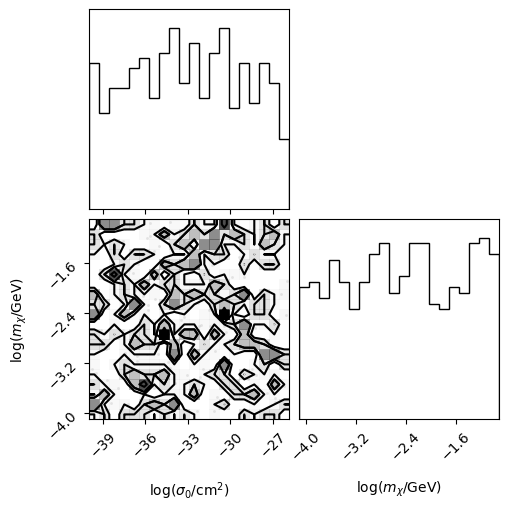

In [10]:
flat_samples = sampler.get_chain(thin=15, flat=True)

print(flat_samples.shape)

labels = [r"$\mathrm{log} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    flat_samples, labels=labels
)

In [103]:
# test log_lik function
log_lik([-34.37890125,-1.05912699], L_obs[:nclusters], nfws_subset[:nclusters], variances_obs[:nclusters])

-6.158063515829541

In [82]:
#test L500_numerical
test_nfw = nfws_subset[1]
test_nfw.L500_numerical(10**-1.05912699, 10**-34.37890125)

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-100): 1.441707237546214e+34, equation(100): 4.441785910379414e+82


ValueError: f(a) and f(b) must have different signs

In [63]:
print(test_nfw.M500/1e14), print(test_nfw.M500/1e14)

4.001657 (+0.24886899999999998, -0.22697399999999998)


In [86]:
nfws_broken = [nfws_subset[i] for i in [1, 3, 4, 5, 7, 8, 10, 11, 12, 13, 18, 19]]
[n.M500.value/1e14 for n in nfws_broken]

[4.001657,
 2.7566229999999994,
 3.0303369999999994,
 4.259752,
 3.5428879999999996,
 2.8318219999999994,
 4.918353999999999,
 3.6478529999999996,
 3.429741999999999,
 3.017628,
 3.6355519999999992,
 3.6869269999999994]

In [88]:
nfws_ok = [nfws_subset[i] for i in [0, 2, 6, 9, 14, 15, 16, 17]]
[n.M500.value/1e14 for n in nfws_ok]

[2.2387739999999994,
 2.6063689999999995,
 1.4547059999999996,
 2.3266959999999997,
 1.8444639999999997,
 1.1438049999999997,
 1.523346,
 1.6715489999999997]

In [ ]:
nfws_broken_test = nfws_subset[1]
Ls = np.linspace(-100, 100)
heating_rate_broken = nfws_broken_test.L500_numerical(10**-1.29541005, 10**-24.42572664 )

In [ ]:
nfws_ok_test = nfws_subset[0]
Ls = np.linspace(-100, 100)
heating_rate_ok = nfws_ok_test.L500_numerical(10**-1.29541005, 10**-24.42572664)

In [ ]:
from matplotlib import pyplot as plt
plt.plot(Ls, heating_rate_broken)
plt.plot(Ls, heating_rate_ok)
plt.yscale('symlog')

plt.ylabel('net heating rate erg/s')
plt.xlabel('log(L500) - 44')